# Assignment 4: Randomized Benchmarking Protocol

Sequence lengths: [1, 5, 10, 20, 30, 50, 75, 100]
Survival probabilities (fidelity): [0.9897, 0.9518, 0.9113, 0.8341, 0.769, 0.6869, 0.6084, 0.5612]

Fitted depolarizing parameter p = 0.98069
Estimated average error per Clifford gate = 0.00965

Fidelity decay plot saved as assignment4_output.png


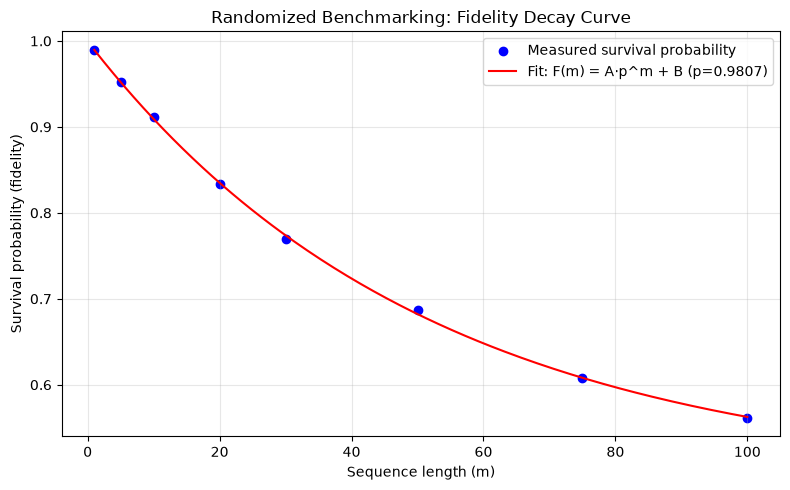

In [1]:
"""
Assignment 4: The Randomized Benchmarking Protocol
Simplified single-qubit Clifford RB implemented manually with Qiskit + Aer,
plotting the fidelity decay curve against sequence length.
"""
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, depolarizing_error

# ---- Define the single-qubit Clifford group generators (simplified set) ----
# Represented as (gate_name, function) pairs; a a full Clifford group has 24 elements,
# here we use products of H, S, X, Y, Z to build random Clifford-like sequences.
clifford_gates = ['h', 'x', 'y', 'z', 's', 'sdg']

def apply_random_clifford(qc, qubit, rng):
    gate = rng.choice(clifford_gates)
    getattr(qc, gate)(qubit)
    return gate

def inverse_gate(qc, qubit, gate):
    inverse_map = {'h': 'h', 'x': 'x', 'y': 'y', 'z': 'z', 's': 'sdg', 'sdg': 's'}
    getattr(qc, inverse_map[gate])(qubit)

# ---- Add a simple depolarizing noise model to simulate a noisy real device ----
noise_model = NoiseModel()
error_1q = depolarizing_error(0.01, 1)  # 1% depolarizing error per gate
noise_model.add_all_qubit_quantum_error(error_1q, clifford_gates)

simulator = AerSimulator(noise_model=noise_model)

# ---- RB Procedure ----
rng = np.random.default_rng(42)
sequence_lengths = [1, 5, 10, 20, 30, 50, 75, 100]
shots = 512
n_sequences = 20  # number of random sequences averaged per length

survival_probabilities = []

for length in sequence_lengths:
    successes = 0
    for _ in range(n_sequences):
        qc = QuantumCircuit(1, 1)
        applied_gates = []

        # Apply the randomized sequence of Clifford gates
        for _ in range(length):
            g = apply_random_clifford(qc, 0, rng)
            applied_gates.append(g)

        # Apply the inverse sequence to return to the initial state |0>
        for g in reversed(applied_gates):
            inverse_gate(qc, 0, g)

        qc.measure(0, 0)

        job = simulator.run(qc, shots=shots)
        counts = job.result().get_counts()
        successes += counts.get('0', 0) / shots

    survival_probabilities.append(successes / n_sequences)

print("Sequence lengths:", sequence_lengths)
print("Survival probabilities (fidelity):", [round(p, 4) for p in survival_probabilities])

# ---- Fit an exponential decay: F(m) = A * p^m + B ----
def exp_decay(m, A, p, B):
    return A * (p ** m) + B

from scipy.optimize import curve_fit
try:
    popt, _ = curve_fit(exp_decay, sequence_lengths, survival_probabilities, p0=[0.5, 0.99, 0.5])
    A, p, B = popt
    error_per_clifford = (1 - p) / 2
    print(f"\nFitted depolarizing parameter p = {p:.5f}")
    print(f"Estimated average error per Clifford gate = {error_per_clifford:.5f}")
except Exception as e:
    print("Curve fit failed:", e)
    A, p, B = 0.5, 0.99, 0.5

# ---- Visualize the results: plot the fidelity decay curve ----
m_fit = np.linspace(min(sequence_lengths), max(sequence_lengths), 200)
plt.figure(figsize=(8, 5))
plt.scatter(sequence_lengths, survival_probabilities, color='blue', label='Measured survival probability')
plt.plot(m_fit, exp_decay(m_fit, A, p, B), color='red', label=f'Fit: F(m) = A·p^m + B (p={p:.4f})')
plt.xlabel("Sequence length (m)")
plt.ylabel("Survival probability (fidelity)")
plt.title("Randomized Benchmarking: Fidelity Decay Curve")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("assignment4_output.png", dpi=120)
print("\nFidelity decay plot saved as assignment4_output.png")
